# CNN Training on ImageNet-100
- Single recipe, from scratch, for Pure Head-to-Head Architectural comparison.
- Models: timm first, torchvision as fallback.
- Only models without a completed, recipe-matching entry in `cnn_training.csv` are trained. Interrupted runs resume from `<model>.resume.pt`.
- Outputs: `checkpoint/pytorch/<model>.pt`, `data/cnn-train-data/cnn_training.csv` (one row per model), `cnn_training_epochs.csv` (one row per epoch).
- Data path: raw ImageFolder -> one-time uint8 memmap cache -> GPU-side augmentation (avoids the 6-core JPEG decoding bottleneck).

Author: Kananelo Chabeli  
Affiliation: University of Cape Town

In [1]:
# !pip install -q timm tqdm pandas ipywidgets   # uncomment on first run
# ipywidgets is needed for tqdm progress bars to render inside Jupyter.

import os, io, json, time, math, copy, gc, queue, hashlib, platform, threading, traceback
from dataclasses import dataclass, field, asdict, replace
from pathlib import Path
from typing import Optional, Any
from concurrent.futures import ThreadPoolExecutor   # used to build the cache without worker processes

import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, timm
import torchvision.transforms as T
from torchvision.ops import roi_align               # batched crop+resize, used for GPU augmentation
from timm.data import Mixup
from tqdm.auto import tqdm

# cuDNN benchmark: lets cuDNN try several convolution algorithms for each layer shape and keep the
# fastest. Our input shapes never change, so the one-off autotuning cost is repaid many times.
torch.backends.cudnn.benchmark = True
# Allows TF32 on the Ada tensor cores for fp32 matmuls: faster, with negligible accuracy impact.
torch.set_float32_matmul_precision("high")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"torch: {torch.__version__}\ntimm: {timm.__version__}\ntorchvision: {torchvision.__version__}\nGPU-Device: {DEVICE}",
      torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

torch: 2.11.0+cu128
timm: 1.0.30
torchvision: 0.26.0+cu128
GPU-Device: cuda NVIDIA GeForce RTX 4060 Ti


C:\Users\chabz\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Paths and configuration

In [3]:
ROOT        = Path.cwd().resolve().parent          # notebook lives in ai-accelerators/notebooks
DATASET_DIR = ROOT / "datasets" / "imageNet-100"   # Kaggle layout: train.X1..X4/<class>/*.JPEG, val.X/<class>/*.JPEG

# The Kaggle ImageNet-100 train split is spread over four folders. Class folders with the SAME name
# in different parts are merged into one class, so train.X1/n01530575 and train.X3/n01530575 are
# the same class. The part number carries no label information.
SPLIT_DIRS = {
    "train": ["train.X1", "train.X2", "train.X3", "train.X4"],
    "val":   ["val.X"],
}

CACHE_DIR   = ROOT / "datasets" / "imageNet-100_cache"   # generated; delete to force a rebuild
CKPT_DIR    = ROOT / "checkpoint" / "pytorch"           # This where PyTorch checkpoints are stored. Read pre-trained models for hardware-deployment.
DATA_DIR    = ROOT / "data" / "cnn-train-data" #training results data is placed.

# Threads, not processes. PIL releases the GIL while decoding a JPEG, so threads give nearly the
# same throughput as processes, and they avoid the DataLoader worker-spawn hang seen on
# Windows/Jupyter. Oversubscribed beyond the core count because part of the work is disk I/O.
CACHE_WORKERS = min(12, (os.cpu_count() or 4) * 2)

# Defining Traing Configuration that applies to all models. 
#This Allows Pure Architectural Comparison of the Models

@dataclass
class TrainConfig:
    num_classes: int = 100           # ImageNet-100 has 100 classes. Change for a different Dataset.
    epochs: int = 100                # Same Epochs for all Models.
    batch_size: int = 256            # effective batch size (micro-batch x accumulation)
    lr: float = 2e-3                 # AdamW peak LR for batch_size above
    weight_decay: float = 0.05       # not applied to BN / bias
    warmup_epochs: int = 5           # linear LR ramp; prevents early divergence at a high peak LR
    min_lr: float = 1e-5             # floor of the cosine decay
    label_smoothing: float = 0.1
    # The mixup and cutmix are efficient  data augmentation techniques (They are state of the art)
    # Literature to reference: Minghan Chen (2026): Lightweight CNN with Mixup and CutMix data augmentation.
    mixup_alpha: float = 0.1         # set both alphas to 0 to disable mixup/cutmix.
    cutmix_alpha: float = 1.0
    mix_prob: float = 0.5            # fraction of batches that get mixed
    train_res: int = 160             # train resolution == cache resolution
    eval_res: int = 224              # val resolution (resize eval_res/eval_crop_pct, center crop eval_res)
    eval_crop_pct: float = 0.875     # standard ImageNet eval protocol: 224/0.875 = 256
    rrc_scale: tuple = (0.35, 1.0)   # RandomResizedCrop scale range (RSB-A3 style)
    clip_grad: float = 5.0           # guards the occasional loss spike on the smaller models
    seed: int = 42                   # Same RandomSeed for result reproducibility
    amp_dtype: str = "bfloat16"      # bf16 has fp32 exponent range, so no gradient scaler needed
    compile: bool = False            # torch.compile (slow warmup per model; excluded from recipe hash)
    limit_batches: Optional[int] = None   # smoke tests only
    debug: bool = False              # debug runs write to separate _debug folders / files

    # The hash fingerprints the recipe and is stored in every CSV row and checkpoint.
    # Change any hyperparameter -> hash changes -> old results stop counting as "done", so two
    # different recipes can never be mixed in one results table. This is what makes the
    # "single recipe" claim verifiable.
    def recipe_hash(self) -> str:
        d = asdict(self)
        for k in ("compile", "limit_batches", "debug"):   # these cannot change the trained weights
            d.pop(k)
        return hashlib.md5(json.dumps(d, sort_keys=True, default=str).encode()).hexdigest()[:8]

In [4]:
CFG = TrainConfig()
print(CFG)

CFG_HASH = CFG.recipe_hash()
print(f"\nrecipe hash: {CFG_HASH}")
print(f"dataset dir exists: {DATASET_DIR.is_dir()}  ->  {DATASET_DIR}")
print(f"cache workers: {CACHE_WORKERS}")

TrainConfig(num_classes=100, epochs=100, batch_size=256, lr=0.002, weight_decay=0.05, warmup_epochs=5, min_lr=1e-05, label_smoothing=0.1, mixup_alpha=0.1, cutmix_alpha=1.0, mix_prob=0.5, train_res=160, eval_res=224, eval_crop_pct=0.875, rrc_scale=(0.35, 1.0), clip_grad=5.0, seed=42, amp_dtype='bfloat16', compile=False, limit_batches=None, debug=False)

recipe hash: f7913ccc
dataset dir exists: True  ->  C:\Users\chabz\MSc\ai-accelerators\datasets\imageNet-100
cache workers: 12


## 2. Dataset cache (one-time) and GPU data loader

### 2.1 Multi-root ImageFolder

A map-style `Dataset` over the four train parts. The alternatives were copying ~15 GB into one
tree (no spare disk), symlinks (awkward on Windows), or `ConcatDataset` of four ImageFolders
(each would build its own class index, silently misaligning labels if a class were missing from
one part).

In [5]:
# This Class is a map-style PyTorch Dataset. There is Nothing that is loaded from the Disk when its created,
# except the directory listing.
# It holds a list of (file_path, integer_label) pairs instead of loading all 130k images into RAM.
# An image is only read FROM disk when __getitem__ is called with its index.

class MultiRootImageFolder(torch.utils.data.Dataset):
    """ImageFolder over several root dirs; class folders with the same name are merged."""

    EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}   # lowercased; this dataset's files are .JPEG

    def __init__(self, roots, classes=None, transform=None):
        roots = [Path(r) for r in roots]
        # Fail immediately on a wrong folder name, rather than silently building an empty dataset.
        for r in roots: assert r.is_dir(), f"missing folder: {r}"

        # Class names = immediate sub-folder names, unioned across roots. sorted() for determinism.
        found = sorted({d.name for r in roots for d in r.iterdir() if d.is_dir()})

        # train is built first and defines the canonical order; val is passed that list.
        self.classes = classes if classes is not None else found

        # Strict check: if val did not contain exactly the same classes, label index 7 would mean
        # different things in the two splits and the accuracy numbers would be wrong but plausible.
        assert set(found) == set(self.classes), (
            f"class mismatch: {len(found)} found vs {len(self.classes)} expected")

        cidx = {c: i for i, c in enumerate(self.classes)}   # WordNet ID (n01530575) -> 0..99

        # rglob walks each root recursively. A file is kept only if its extension is an image type
        # AND its parent folder is a known class, so the label is always the containing folder.
        # sorted() makes the cache byte-identical on every run and on every OS.
        self.samples = sorted(
            (str(p), cidx[p.parent.name])
            for r in roots for p in r.rglob("*")
            if p.suffix.lower() in self.EXT and p.parent.name in cidx)
        assert self.samples, f"no images found under {roots}"

        self.transform = transform
        # This is default torchvision's loader. It opens the file with PIL and calls .convert("RGB").
        # This is important for ImageNet, which contains a few grayscale and CMYK image files, which would
        # lead to variable image channels, possibly crashing batching.
        self.loader = torchvision.datasets.folder.default_loader   # PIL -> RGB

    def __len__(self): return len(self.samples) # this function is self explanatroy.

    # This looks up (path,label) and decodes JPEG into a PIL image (this is the expensive step, costing a few ms of CPU)
    # It then applies the given transform (transform reshapes to 160x160).
    # The result is a uint8 tensor of shape (3,160,160) in [0,255], plus an int label.
    # NOTE: uint8, NOT scaled to [0,1] - the float conversion and normalisation happen later on the GPU.
    #
    # Why train at 160px but evaluate at 224px?
    # Paper: Touvron et al. (2019), "Fixing the Train-Test Resolution Discrepancy".
    # Short answer: random-resized-crop zooms objects in during training,
    # so objects look larger in training than at test time.
    # Testing at a somewhat higher resolution than the training one compensates for this.
    def __getitem__(self, i):
        path, y = self.samples[i]
        img = self.loader(path)
        return (self.transform(img) if self.transform else img), y

### 2.2 One-time uint8 cache



In [6]:
# This function converts training data (about 130K images) JPEGs into two files:
#   train_160_x.npy : one uint8 array of shape (N,160,160,3), every image already resized and cropped.
#   train_160_y.npy : integer labels
# It only runs once; later runs skip it.
# This cache is necessary because decoding a JPEG and resizing it costs a few milliseconds of CPU.
# A 6-core CPU manages roughly 600-900 img/s, while a mobile CNN on the GPU can consume several
# thousand - so decoding every epoch would starve the GPU, and we would pay that cost 100 epochs x N models.
# This cache pays the decode cost once, after which an epoch is just reading raw bytes from the file.
# The CACHE directory is not tracked by git.
#
# Information Loss: training images are centre-cropped to 160x160 once, so each train image has a
# fixed crop and the edges of non-square images are gone. Data augmentation later crops within that
# 160x160 square. This is a deliberate trade-off of augmentation variety for speed. Every model is
# affected identically, so it cannot bias the ranking.

def build_cache(split: str, res: int, resize_to: int):
    """Multi-folder ImageNet-100 -> uint8 NHWC .npy memmap + labels. Skipped if it already exists.

    split     : "train" or "val" (keys of SPLIT_DIRS)
    res       : final square size stored in the cache
    resize_to : short-side resize applied before the centre crop
    """
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    fx, fy = CACHE_DIR / f"{split}_{res}_x.npy", CACHE_DIR / f"{split}_{res}_y.npy"
    # Resolution is in the filename, so changing train_res builds a NEW cache instead of
    # silently reusing a stale one at the wrong size.
    if fx.exists() and fy.exists():
        print(f"{split}@{res}: cache already present, skipping")
        return fx, fy

    # Reuse the class order from whichever split was built first (train), so labels align.
    cls_file = CACHE_DIR / "classes.json"
    classes = json.loads(cls_file.read_text()) if cls_file.exists() else None

    tf = T.Compose([T.Resize(resize_to), T.CenterCrop(res), T.PILToTensor()])   # -> uint8 CHW
    ds = MultiRootImageFolder([DATASET_DIR / d for d in SPLIT_DIRS[split]], classes, tf)
    assert len(ds.classes) == CFG.num_classes, f"{split}: found {len(ds.classes)} classes"
    print(f"{split}: {len(ds)} images, {len(ds.classes)} classes")
    if classes is None:
        cls_file.write_text(json.dumps(ds.classes))   # train runs first, so train defines the class order

    # open_memmap creates the .npy on disk and maps it, so the ~10 GB array is never held in RAM.
    tmp = CACHE_DIR / f"{split}_{res}_x.tmp.npy"
    mm = np.lib.format.open_memmap(tmp, mode="w+", dtype=np.uint8, shape=(len(ds), res, res, 3))
    ys = np.empty(len(ds), np.int64)

    def load(i):
        x, y = ds[i]                             # x: uint8 CHW
        return x.permute(1, 2, 0).numpy(), y     # -> HWC, the layout stored in the cache

    CHUNK = 512          # progress-bar granularity, and bounds how much the pool holds at once
    try:
        with ThreadPoolExecutor(max_workers=CACHE_WORKERS) as ex:
            for s in tqdm(range(0, len(ds), CHUNK), desc=f"cache {split}@{res}"):
                e = min(s + CHUNK, len(ds))
                for j, (x, y) in enumerate(ex.map(load, range(s, e))):
                    mm[s + j] = x
                    ys[s + j] = y
        mm.flush()
    finally:
        del mm           # Windows will not rename a file while a memmap handle is open

    np.save(fy, ys)
    # Atomic publish: the array is written to .tmp.npy and only renamed once complete, so an
    # interrupted build can never be mistaken for a finished cache.
    os.replace(tmp, fx)
    return fx, fy


# This function runs build_cache for training and validation.
# Train is built FIRST, because it writes classes.json and so defines the canonical class order.
# Val uses the standard eval protocol: resize the short side to 224/0.875 = 256, then centre-crop 224.
def ensure_caches(cfg: TrainConfig):
    build_cache("train", cfg.train_res, cfg.train_res)
    build_cache("val", cfg.eval_res, int(round(cfg.eval_res / cfg.eval_crop_pct)))

### 2.3 Normalisation and GPU-side augmentation

In [7]:
# These are standard ImageNet-1K statistics. They are per-channel (R,G,B) means and standard
# deviations over the ImageNet-1k training set, and the defaults used by torchvision and timm.
# ImageNet-100 is a random-ish subset of ImageNet-1k, so its own statistics would be nearly identical.
# Multiplied by 255 because our cached tensors are raw uint8 in [0,255], not floats in [0,1].
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1) * 255
STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1) * 255

def normalize(x):  # x float NCHW in [0,255]
    return (x - MEAN.to(x.device)) / STD.to(x.device)


# This function applies two standard ImageNet training augmentations to the whole batch on GPU:
#   1. RandomResizedCrop - each image gets a random crop covering 35-100% of its area, at a random
#      aspect ratio in [3/4, 4/3], resized to out_res. From the Inception line of work
#      (Szegedy et al., 2015); the default in torchvision and timm.
#   2. Horizontal flip with probability 0.5.
# Each image in the batch gets an INDEPENDENT random draw.
#
# The cache stores fixed, pre-cropped uint8 images,
# so the usual torchvision augmentation pipeline (which runs on the CPU per image) would bring back
# the CPU bottleneck we built the cache to avoid. Doing it on the GPU makes augmentation nearly free.
#
# APPROXIMATION TO DECLARE: torchvision's RandomResizedCrop retries up to 10 times to fit a box
# inside the image and falls back to a centre crop. This version draws once and clamps the box to
# the image, so the distributions differ slightly at extreme scale/aspect draws. Applied
# identically to every model, so it cannot bias the comparison.
def gpu_train_aug(x_u8, out_res, scale, ratio=(3/4, 4/3)):
    """Per-sample RandomResizedCrop (via roi_align) + horizontal flip, entirely on GPU."""
    n, s = x_u8.shape[0], x_u8.shape[1]          # batch size, cached square size (160)
    x = x_u8.permute(0, 3, 1, 2).float()         # NHWC uint8 -> NCHW float
    dev = x.device

    #  sample one crop box per image
    area = s * s * torch.empty(n, device=dev).uniform_(*scale)
    # log-uniform aspect ratio keeps portrait and landscape equally likely
    ar = torch.exp(torch.empty(n, device=dev).uniform_(math.log(ratio[0]), math.log(ratio[1])))
    w = torch.sqrt(area * ar).clamp(max=s)       # clamp keeps the box inside the image
    h = torch.sqrt(area / ar).clamp(max=s)
    x0 = torch.rand(n, device=dev) * (s - w)     # top-left corner, uniform over valid positions
    y0 = torch.rand(n, device=dev) * (s - h)

    # roi_align expects boxes as [batch_index, x1, y1, x2, y2]. It crops and bilinearly resizes
    # all n boxes in ONE batched call - this is what makes a per-sample crop cheap.
    boxes = torch.stack([torch.arange(n, device=dev, dtype=x.dtype), x0, y0, x0 + w, y0 + h], 1)
    # sampling_ratio=2 averages a 2x2 grid per output pixel: mild anti-aliasing. Crops here are
    # mostly UPscaled (box <= 160 -> 160), so aliasing is not a practical concern.
    x = roi_align(x, boxes, (out_res, out_res), spatial_scale=1.0, sampling_ratio=2, aligned=True)

    # horizontal flip, p=0.5, independently per image 
    flip = torch.rand(n, device=dev) < 0.5
    return torch.where(flip[:, None, None, None], x.flip(3), x)

### 2.4 Cached loader

In [9]:
# This class serves mini-batches from the cached .npy files, replacing PyTorch's DataLoader.
# Each iteration yields a batch of raw uint8 images (NHWC) and int64 labels, both already pinned
# in memory and ready to copy to the GPU.
#
# How it works:
# - Memory-mapped array does not load the 10GB train cache into RAM. The OS pages in only what is
#   touched, and after the first epoch most of it sits in the page cache, so later epochs read
#   from RAM rather than from disk.
# - Each epoch gets a new random permutation of the sample indices, seeded with seed + epoch.
#   The order is random across epochs, but still reproducible - and a resumed run gets the same
#   order for a given epoch.
#
# This is the second half of the speed solution. The cache defined above removes the JPEG decoding
# bottleneck, and this class removes the per-image Python overhead of a normal Dataset + DataLoader.
# A batch is simply one fancy-indexing call that copies about 20MB, making the loader cost very
# little on a 6-core CPU while the GPU stays busy.

class CachedLoader:
    """Memmap-backed loader with a background prefetch thread. Yields pinned uint8 NHWC + int64 labels."""

    def __init__(self, split, res, batch_size, train, seed=0, limit_batches=None, prefetch=4):
        self.x = np.load(CACHE_DIR / f"{split}_{res}_x.npy", mmap_mode="r")   # lazy; not in RAM
        self.y = torch.from_numpy(np.load(CACHE_DIR / f"{split}_{res}_y.npy"))
        self.bs, self.train, self.seed, self.prefetch = batch_size, train, seed, prefetch
        self.n = len(self.y); self.epoch = 0
        # TRAIN drops the last partial batch: mixup needs a full batch, and BN statistics are
        # steadier at a constant batch size. 130000 // 256 = 507 batches, so 128 images are
        # skipped each epoch - a DIFFERENT 128 every time, since the permutation changes.
        # VAL uses ceil() so that all 5000 validation images are evaluated.
        nb = self.n // batch_size if train else math.ceil(self.n / batch_size)
        self.nb = min(nb, limit_batches) if limit_batches else nb

    def __len__(self): return self.nb

    # Same role as DistributedSampler.set_epoch: changes the shuffle for the coming epoch.
    def set_epoch(self, e): self.epoch = e

    def _produce(self, q):
        """Producer thread: prepares batches ahead of the GPU and puts them on the queue."""
        try:
            idx = (np.random.default_rng(self.seed + self.epoch).permutation(self.n)
                   if self.train else np.arange(self.n))
            for b in range(self.nb):
                # Indices are sorted WITHIN a batch because sequential memmap reads are faster.
                # The order of images inside a batch is irrelevant to training.
                bi = np.sort(idx[b * self.bs:(b + 1) * self.bs])   # sorted -> faster memmap reads
                # pin_memory() lets the later .to(device, non_blocking=True) copy asynchronously.
                q.put((torch.from_numpy(self.x[bi]).pin_memory(), self.y[bi].pin_memory()))
            q.put(None)                       # sentinel: end of epoch
        except Exception as e:
            q.put(e)                          # re-raised in the consumer, so errors are not swallowed

    def __iter__(self):
        # Bounded queue: the producer can run at most `prefetch` batches ahead, which overlaps
        # disk/RAM reading with GPU compute without letting pinned memory grow without limit.
        q = queue.Queue(self.prefetch)
        threading.Thread(target=self._produce, args=(q,), daemon=True).start()
        while True:
            item = q.get()
            if item is None: return
            if isinstance(item, Exception): raise item
            yield item

## 3. Model registry (timm first, torchvision fallback)

In [10]:
# ADD / REMOVE MODELS HERE (string, or dict with overrides)
# This is designed to be as flexible as possible to allow for experimentation with different models.
#
# Accepted entry forms:
#   "mobilenetv2_100"                                         -> auto: timm first, else torchvision
#   {"name": "shufflenet_v2_x1_0", "source": "torchvision"}   -> force a library
#   {"name": "efficientnet_b0", "micro_batch_size": 128}      -> smaller micro-batch if it OOMs
#   {"name": "inception_v3", "kwargs": {"aux_logits": False}} -> constructor arguments
#
# NOTE: the model name is the key for both the CSV row and the checkpoint filename, so the same
# name must not appear twice (e.g. inception_v3 from BOTH timm and torchvision would collide).

In [11]:
MODELS = [
    "mobilenetv1_100",
    "mobilenetv2_100",
    "mobilenetv3_small_100",
    "mobilenetv3_large_100",
    "mobilenetv4_conv_small",
    "mobilenetv4_hybrid_medium", #this contains attention headers, which are interesting to investigate on TPU and
    # Hailo to compile. Keep it for deployable test case.

    "efficientnet_lite0",        # INT8-friendly: ReLU6, no squeeze-excite
    "efficientnet_b0",           # SiLU + SE: quantizes, but may not fully map onto the accelerators

    "ghostnet_100",
    "ghostnetv2_100",
    "ghostnetv3_100",

    {"name": "shufflenet_v2_x1_0", "source": "torchvision"},
    #shufflenetv1 is  neither in torchvision.models nor timmn. will need to be sourced from external implementatoions

    "squeezenet1_0",
    "squeezenet1_1",    #squeezeNext not found in torchvision.models nor timm, will need to be sourced from external repo.

    # --- Inception lineage: NOT edge-targeted, kept commented out as heavyweight reference points.
    # These need aux_logits=False (otherwise they return a tuple in train mode and the loss fails)
    # and a smaller micro-batch to fit in 16 GB.
    # {"name": "googlenet",    "source": "torchvision", "kwargs": {"aux_logits": False}},
    # {"name": "inception_v3", "source": "torchvision", "kwargs": {"aux_logits": False}, "micro_batch_size": 128},
    # {"name": "inception_v4",        "micro_batch_size": 64},
    # {"name": "inception_resnet_v2", "micro_batch_size": 64},
    # {"name": "legacy_xception",     "micro_batch_size": 128},
]

In [12]:
# ModelSpec is a small record describing the model to train
# name: is the architecture
# source: forces timm or torchvision, and None means auto.
# kwargs: extra constructor arguments passed to the model creation routine
# micro_batch_size: this is an optional per-model override for the models that run out of GPU memory.

@dataclass
class ModelSpec:
    name: str
    source: Optional[str] = None            # None = auto (timm -> torchvision); or "timm" / "torchvision"
    kwargs: dict = field(default_factory=dict)   # e.g. {"drop_path_rate": 0.1}
    micro_batch_size: Optional[int] = None  # set smaller than CFG.batch_size if OOM; accumulation is automatic


# This function accepts plain strings, dicts, or ModelSpec objects and normalizes them all to ModelSpec.
# This ensures that adding or removing a model is just a one-line edit.
def as_spec(m) -> ModelSpec:
    return m if isinstance(m, ModelSpec) else ModelSpec(m) if isinstance(m, str) else ModelSpec(**m)


# Implements the "timm first, torchvision fallback" rule and returns WHICH library supplied the model.
# pretrained=False / weights=None give random initialisation - required for "retrain from scratch
# under one recipe"; a pretrained start would smuggle each model's original training recipe back in.
#
# LIMITATION TO DECLARE: timm and torchvision use slightly different default weight initialisations.
# The recipe is identical across models, the init is not. This is a small residual confound; the
# source library is recorded in every CSV row and checkpoint so results stay traceable.
def build_model(spec: ModelSpec, num_classes: int):
    if spec.source in (None, "timm") and timm.is_model(spec.name):
        return timm.create_model(spec.name, pretrained=False, num_classes=num_classes, **spec.kwargs), "timm"
    # list_models(module=torchvision.models) restricts the lookup to CLASSIFICATION models, so a
    # detection or segmentation model cannot be matched by accident.
    if spec.source in (None, "torchvision") and spec.name in torchvision.models.list_models(module=torchvision.models):
        return torchvision.models.get_model(spec.name, weights=None, num_classes=num_classes, **spec.kwargs), "torchvision"
    raise ValueError(f"'{spec.name}' not found (source={spec.source})")


# This function returns the model's size: parameters in millions, and MACs (which translate to FLOPs) in billions,
# for one image at the given resolution.
#
# Parameters are counted directly from the weight tensors.
# MACs are computed from PyTorch's FlopCounterMode, which intercepts one forward pass and tallies
# the FLOPs of each op. These are theoretical and hardware-independent.
# Divided by 2 because one multiply-accumulate = 2 FLOPs. Input values are irrelevant (zeros are
# fine) because the count depends only on tensor shapes.
def complexity(model, res):
    from torch.utils.flop_counter import FlopCounterMode
    model = copy.deepcopy(model).eval().cpu()   # deep copy so the real model and the GPU are untouched
    params = sum(p.numel() for p in model.parameters())
    with torch.no_grad(), FlopCounterMode(display=False) as fc:
        model(torch.zeros(1, 3, res, res))
    return params / 1e6, fc.get_total_flops() / 2 / 1e9   # (M params, GMACs)


# This function is just a dry run on the models that does no training. For each model, it
# builds the model, runs complexity at a 224 image, and returns a table of source library, parameters, and GMACs.
# It catches typos, missing architectures, bad kwargs and forward-pass crashes in SECONDS,
# before committing GPU hours.
# CAUTION: any exception is labelled NOT AVAILABLE, including a forward-pass failure in a model
# that does exist - always read the error column before concluding that a name is missing.
def preview_models(models=MODELS, cfg=CFG, res=224):
    rows = []
    for m in map(as_spec, models):
        try:
            net, src = build_model(m, cfg.num_classes)
            p, g = complexity(net, res)
            rows.append(dict(model=m.name, source=src, params_M=round(p, 2),
                             GMACs=round(g, 3), res=res, error=""))
        except Exception as e:
            rows.append(dict(model=m.name, source="NOT AVAILABLE", params_M=None,
                             GMACs=None, res=res, error=f"{type(e).__name__}: {e}"[:120]))
    return pd.DataFrame(rows)


# Separate from preview_models: forward-passes every model at the TRAINING resolution (160px).
# Some architectures (Inception family, anything with valid-padded convolutions) work at 224 but
# fail at 160 because a feature map becomes too small. Every row must show ok=True before training.
def check_forward(models=MODELS, cfg=CFG):
    rows = []
    for m in map(as_spec, models):
        try:
            net, _ = build_model(m, cfg.num_classes)
            net.eval()
            with torch.no_grad():
                out = net(torch.zeros(2, 3, cfg.train_res, cfg.train_res))
            # A tuple output (e.g. aux_logits still enabled) would break the loss, so check the type too.
            ok = torch.is_tensor(out) and out.shape == (2, cfg.num_classes)
            rows.append(dict(model=m.name, ok=ok,
                             out=str(tuple(out.shape)) if torch.is_tensor(out) else type(out).__name__,
                             error=""))
        except Exception as e:
            rows.append(dict(model=m.name, ok=False, out="", error=f"{type(e).__name__}: {e}"[:120]))
    return pd.DataFrame(rows)


## Comment on Theoretical MACs: FlopCounterMode counts convolutions, matrix multiplications, and attention
# but not BatchNorm, activations, pooling, concatenation, or channel shuffle. It matches the "MACs" convention
# in the literature, and is a reason why MACs correlate poorly with latency on shuffle- and depthwise-heavy
# models - which is precisely one of the things this study sets out to measure.

# Params include the 100-class classification head, so they are smaller than the published
# 1000-class figures. Small models are affected most (MobileNetV3-small loses roughly 1M).

## 4. Results store (CSV) — decides what still needs training

In [13]:
# This class is like a bookkeeping layer. It owns the two CSV files and the checkpoint locations.
# It is implemented here to keep track of the models' trained checkpoints, so that models are not
# retrained on every run.
#
# A model counts as DONE only if ALL THREE hold:
#   1. checkpoint/pytorch/<name>.pt exists
#   2. cnn_training.csv has a row for it with status == "completed"
#   3. that row's recipe_hash equals the CURRENT recipe's hash
# Requiring all three means: deleting a checkpoint triggers a retrain instead of leaving a CSV row
# pointing at weights that no longer exist, and changing a hyperparameter invalidates every prior
# result instead of silently mixing two recipes in one table.
#
# LIMITATION: this is a read-modify-write on whole CSV files. Fine for one training process;
# do NOT run two notebooks against the same CSV at once, or rows will be lost.

class ResultsStore:
    def __init__(self, cfg: TrainConfig):
        sub = "_debug" if cfg.debug else ""          # smoke tests are fully isolated from real results
        self.data_dir = DATA_DIR / sub if sub else DATA_DIR
        self.ckpt_dir = CKPT_DIR / sub if sub else CKPT_DIR
        self.data_dir.mkdir(parents=True, exist_ok=True); self.ckpt_dir.mkdir(parents=True, exist_ok=True)
        self.summary_csv = self.data_dir / "cnn_training.csv"          # one row per model
        self.epochs_csv = self.data_dir / "cnn_training_epochs.csv"    # one row per model per epoch

    # ---- io helpers ----
    def _read(self, p): return pd.read_csv(p) if p.exists() else pd.DataFrame()

    # Write to a temp file, then rename. os.replace is atomic, so a crash mid-write can never
    # leave a half-written / corrupted CSV.
    def _write(self, df, p):
        tmp = p.with_suffix(".tmp"); df.to_csv(tmp, index=False); os.replace(tmp, p)

    def summary(self): return self._read(self.summary_csv)
    def epochs(self): return self._read(self.epochs_csv)

    # ---- checkpoint paths ----
    def final_ckpt(self, name): return self.ckpt_dir / f"{name}.pt"          # the deliverable
    def resume_ckpt(self, name): return self.ckpt_dir / f"{name}.resume.pt"  # scratch; deleted on success

    # ---- the skip decision ----
    def is_done(self, name, recipe_hash) -> bool:
        df = self.summary()
        if df.empty or not self.final_ckpt(name).exists(): return False
        r = df[(df.model == name) & (df.status == "completed")]
        # str() because pandas can read an all-digit hash back as a number.
        return (not r.empty) and (str(r.iloc[-1].recipe_hash) == recipe_hash)

    # ---- writes ----
    # Replace this model's row rather than appending a duplicate, so a retrain overwrites its result.
    def upsert_summary(self, row: dict):
        df = self.summary()
        if not df.empty: df = df[df.model != row["model"]]
        self._write(pd.concat([df, pd.DataFrame([row])], ignore_index=True), self.summary_csv)

    def append_epoch(self, row: dict):
        self._write(pd.concat([self.epochs(), pd.DataFrame([row])], ignore_index=True), self.epochs_csv)

    # On resume, discard any epoch rows logged beyond the checkpoint. Without this, a crash between
    # "epoch logged" and "checkpoint saved" would leave duplicate epoch numbers in the curves.
    def drop_epochs(self, name, after_epoch=0):
        df = self.epochs()
        if not df.empty:
            self._write(df[~((df.model == name) & (df.epoch > after_epoch))], self.epochs_csv)

## 5. ModelTrainer

In [14]:
# Wraps the complete train/validate loop for ONE model. The same object is used for every
# architecture, which is what enforces the single shared recipe.
#
# Key design points:
# - Gradient accumulation keeps the EFFECTIVE batch at CFG.batch_size for every model. A model
#   that does not fit sets micro_batch_size, and the trainer accumulates
#   batch_size / micro_batch_size micro-batches before stepping the optimiser. So the LR scaling
#   stays valid across models. (Note: BatchNorm statistics are still computed per
#   MICRO-batch, so accumulation is not perfectly equivalent to a true large batch.)
# - No weight decay on BatchNorm gains or biases: decaying 1-D parameters hurts accuracy, and
#   excluding them is standard in modern ImageNet recipes.
# - LR is computed per optimiser STEP, not per epoch, giving a smooth warmup + cosine curve.
# - bfloat16 autocast for the forward pass, loss in fp32. bf16 has the same exponent range as fp32,
#   so unlike fp16 it needs no gradient scaler.
# - channels_last memory format: the layout cuDNN's tensor-core convolution kernels prefer.
#
# EVALUATION Note: the official validation split is used both for per-epoch logging
# and for the final reported number. The headline top1 is the FINAL epoch, not the best epoch
# (best_top1 is logged separately but is not the reported figure), which avoids selecting on the
# test set. If hyperparameters are tuned later, carve a minival out of the train split.

class ModelTrainer:
    def __init__(self, spec: ModelSpec, cfg: TrainConfig, store: ResultsStore, device=DEVICE):
        self.spec, self.cfg, self.store, self.device = spec, cfg, store, device
        self.amp_dtype = getattr(torch, cfg.amp_dtype)          # "bfloat16" -> torch.bfloat16

        # Gradient accumulation: effective batch = micro_bs x accum = cfg.batch_size, always.
        self.micro_bs = spec.micro_batch_size or cfg.batch_size
        assert cfg.batch_size % self.micro_bs == 0, "batch_size must be divisible by micro_batch_size"
        self.accum = cfg.batch_size // self.micro_bs

        # Mixup/CutMix produces SOFT targets, so label smoothing is applied by the Mixup object
        # itself on that path; the plain path applies it inside the loss instead.
        self.mixup = (Mixup(mixup_alpha=cfg.mixup_alpha, cutmix_alpha=cfg.cutmix_alpha, prob=cfg.mix_prob,
                            switch_prob=0.5, mode="batch", label_smoothing=cfg.label_smoothing,
                            num_classes=cfg.num_classes)
                      if (cfg.mixup_alpha > 0 or cfg.cutmix_alpha > 0) else None)

    # helpers
    # Same weight init and same data order for every model. NOTE: cudnn.benchmark leaves some
    # non-determinism, so two runs with the same seed can differ slightly. Run 2-3 seeds on a few
    # models to estimate that training noise before declaring small accuracy gaps meaningful.
    @staticmethod
    def _seed(s):
        import random; random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

    # Two param groups: weight decay on conv/linear WEIGHTS only, never on BN gains or biases.
    # p.ndim <= 1 catches BatchNorm weight/bias and any 1-D parameter.
    def _param_groups(self, model):
        decay, no_decay = [], []
        for n, p in model.named_parameters():
            if p.requires_grad: (no_decay if p.ndim <= 1 or n.endswith(".bias") else decay).append(p)
        return [{"params": decay, "weight_decay": self.cfg.weight_decay},
                {"params": no_decay, "weight_decay": 0.0}]

    # Linear warmup for warmup_epochs, then cosine decay from lr down to min_lr.
    # Evaluated per optimiser step so the curve is smooth rather than a staircase.
    def _lr_at(self, step, steps_per_epoch):
        c = self.cfg; warm = c.warmup_epochs * steps_per_epoch; total = c.epochs * steps_per_epoch
        if step < warm: return c.lr * (step + 1) / warm
        t = (step - warm) / max(1, total - warm)     # progress 0->1 through the cosine phase
        return c.min_lr + 0.5 * (c.lr - c.min_lr) * (1 + math.cos(math.pi * t))

    # train / eval
    def _train_epoch(self, fmodel, opt, loader, epoch, step, steps_per_epoch):
        c = self.cfg; fmodel.train(); loader.set_epoch(epoch)    # new shuffle for this epoch
        loss_sum = torch.zeros((), device=self.device); n_micro = 0; seen = 0
        opt.zero_grad(set_to_none=True)
        for i, (x, y) in enumerate(loader):
            # non_blocking works because the loader pinned these tensors: the copy overlaps compute.
            x = x.to(self.device, non_blocking=True); y = y.to(self.device, non_blocking=True)
            # crop + flip + normalise, all on GPU; channels_last for the tensor-core kernels.
            x = normalize(gpu_train_aug(x, c.train_res, c.rrc_scale)).contiguous(memory_format=torch.channels_last)
            if self.mixup is not None: x, t = self.mixup(x, y)   # t = soft targets

            with torch.autocast(self.device, dtype=self.amp_dtype):
                out = fmodel(x)
            out = out.float()                                    # loss computed in fp32 for stability
            loss = (F.cross_entropy(out, t) if self.mixup is not None
                    else F.cross_entropy(out, y, label_smoothing=c.label_smoothing))

            # Divide by accum so accumulated gradients average the micro-batches instead of summing
            # them - this is what makes accumulation equivalent to one large batch.
            (loss / self.accum).backward()
            loss_sum += loss.detach(); n_micro += 1; seen += len(y)

            if (i + 1) % self.accum == 0:                        # one real optimiser step
                lr = self._lr_at(step, steps_per_epoch)
                for g in opt.param_groups: g["lr"] = lr          # set LR on BOTH param groups
                if c.clip_grad: torch.nn.utils.clip_grad_norm_(fmodel.parameters(), c.clip_grad)
                opt.step(); opt.zero_grad(set_to_none=True); step += 1

        tl = (loss_sum / max(1, n_micro)).item()
        # Fail loudly rather than spending hours producing a dead model.
        if not math.isfinite(tl): raise FloatingPointError("train loss is NaN/inf (try lower lr)")
        return tl, step, seen

    # inference_mode is stronger than no_grad: it also skips autograd version tracking.
    @torch.inference_mode()
    def _evaluate(self, fmodel, loader):
        fmodel.eval(); c1 = c5 = n = 0; ls = 0.0
        for x, y in loader:
            x = x.to(self.device, non_blocking=True); y = y.to(self.device, non_blocking=True)
            # NO augmentation at eval time - the val cache is already resized and centre-cropped.
            x = normalize(x.permute(0, 3, 1, 2).float()).contiguous(memory_format=torch.channels_last)
            with torch.autocast(self.device, dtype=self.amp_dtype):
                out = fmodel(x)
            out = out.float(); ls += F.cross_entropy(out, y, reduction="sum").item()
            top5 = out.topk(5, 1).indices; hit = top5 == y[:, None]
            c1 += hit[:, 0].sum().item()        # top-1: the rank-0 prediction is correct
            c5 += hit.any(1).sum().item()       # top-5: the true class is anywhere in the top 5
            n += len(y)
        return 100 * c1 / n, 100 * c5 / n, ls / n

    #  main entry 
    def run(self) -> dict:
        """Train to completion (or resume), save the checkpoint, return the CSV summary row."""
        spec, c, st = self.spec, self.cfg, self.store
        self._seed(c.seed)

        model, source = build_model(spec, c.num_classes)
        params_m, gmacs = complexity(model, 224)                 # while still on CPU: cheap
        model = model.to(self.device).to(memory_format=torch.channels_last)
        # fmodel is what we CALL; model is what we SAVE. torch.compile wraps the module, so keeping
        # both references means the state_dict keys stay clean and loadable without compile.
        fmodel = torch.compile(model) if c.compile else model
        opt = torch.optim.AdamW(self._param_groups(model), lr=c.lr, fused=(self.device == "cuda"))

        train_dl = CachedLoader("train", c.train_res, self.micro_bs, True, c.seed, c.limit_batches)
        val_dl = CachedLoader("val", c.eval_res, 500, False, 0, c.limit_batches)
        # Optimiser steps per epoch = micro-batches / accumulation. The LR schedule is defined over
        # these, so it is identical regardless of a model's micro_batch_size.
        steps_per_epoch = max(1, len(train_dl) // self.accum)

        # resume an interrupted run of the SAME recipe
        start_epoch, step, best = 0, 0, (-1.0, 0)
        rp = st.resume_ckpt(spec.name)
        if rp.exists():
            ck = torch.load(rp, map_location=self.device, weights_only=False)
            if ck.get("recipe_hash") == c.recipe_hash():
                # Optimiser state matters too: AdamW's moment estimates would otherwise restart cold.
                model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
                start_epoch, step, best = ck["epoch"], ck["step"], tuple(ck["best"])
                print(f"  resumed {spec.name} from epoch {start_epoch}")
            else:
                print("  resume file has a different recipe hash -> starting fresh")
        st.drop_epochs(spec.name, after_epoch=start_epoch)       # remove orphaned epoch rows

        if self.device == "cuda": torch.cuda.reset_peak_memory_stats()
        t_train = 0.0; top1 = top5 = vloss = float("nan")

        # epoch loop
        for epoch in range(start_epoch, c.epochs):
            # synchronize() before and after: CUDA calls are async, so without it the timing would
            # measure how fast we QUEUED the work, not how long the GPU took.
            if self.device == "cuda": torch.cuda.synchronize()
            t0 = time.time()
            tl, step, seen = self._train_epoch(fmodel, opt, train_dl, epoch, step, steps_per_epoch)
            if self.device == "cuda": torch.cuda.synchronize()
            dt = time.time() - t0; t_train += dt

            top1, top5, vloss = self._evaluate(fmodel, val_dl)
            if top1 > best[0]: best = (top1, epoch + 1)          # tracked, but NOT the reported figure

            st.append_epoch(dict(model=spec.name, epoch=epoch + 1, train_loss=tl, val_loss=vloss, top1=top1, top5=top5,
                                 lr=opt.param_groups[0]["lr"], epoch_time_s=dt, img_per_s=seen / dt))
            print(f"  [{spec.name}] ep {epoch+1:3d}/{c.epochs} loss {tl:.3f} | top1 {top1:.2f} top5 {top5:.2f} | {dt:.0f}s ({seen/dt:.0f} img/s)")

            # Checkpoint EVERY epoch: a crash, a power cut or a Windows update costs one epoch, not the run.
            torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), epoch=epoch + 1, step=step,
                            best=best, recipe_hash=c.recipe_hash()), rp)

        # final deliverable checkpoint 
        # Carries everything needed to rebuild the model later (ONNX export, quantization, etc.)
        # without consulting this notebook: name, source library, kwargs, class list, full config.
        final = dict(model=model.state_dict(), name=spec.name, source=source, kwargs=spec.kwargs,
                     num_classes=c.num_classes, classes=json.loads((CACHE_DIR / "classes.json").read_text()),
                     config=asdict(c), recipe_hash=c.recipe_hash(), top1=top1, top5=top5)
        torch.save(final, st.final_ckpt(spec.name))
        if rp.exists(): rp.unlink()                              # resume file no longer needed

        # n_ep counts epochs run IN THIS SESSION, so avg_epoch_s stays correct after a resume.
        n_ep = max(1, c.epochs - start_epoch)
        return dict(model=spec.name, source=source, status="completed", recipe_hash=c.recipe_hash(),
                    epochs=c.epochs, top1=top1, top5=top5, val_loss=vloss, best_top1=best[0], best_epoch=best[1],
                    params_M=round(params_m, 3), GMACs_224=round(gmacs, 4),
                    train_res=c.train_res, eval_res=c.eval_res, batch_size=c.batch_size, micro_batch_size=self.micro_bs,
                    train_time_min=round(t_train / 60, 2), avg_epoch_s=round(t_train / n_ep, 1),
                    peak_vram_gb=round(torch.cuda.max_memory_allocated() / 2**30, 2) if self.device == "cuda" else None,
                    seed=c.seed, amp_dtype=c.amp_dtype, kwargs=json.dumps(spec.kwargs),
                    # Library versions are recorded because an architecture's implementation can
                    # change between releases - needed for reproducibility in the thesis.
                    gpu=torch.cuda.get_device_name(0) if self.device == "cuda" else "cpu",
                    torch=torch.__version__, timm=timm.__version__, torchvision=torchvision.__version__,
                    checkpoint=str(st.final_ckpt(spec.name).relative_to(ROOT)),
                    finished_at=time.strftime("%Y-%m-%d %H:%M:%S"), error="")

## 6. Driver: trains only what is missing

In [15]:
# Builds the caches if needed, works out which models still need training, and runs them one at a
# time. A failure in ONE model is caught, logged with status="failed", and does not stop the sweep -
# so an overnight run of 14 models is not lost to a single OOM. Failed models have no "completed"
# row, so they are simply retried on the next run.

def run_all(models=MODELS, cfg: TrainConfig = CFG, force=()):
    """force: model names to retrain even if already completed."""
    ensure_caches(cfg)                       # no-op once the caches exist
    store = ResultsStore(cfg)
    specs = [as_spec(m) for m in models]

    pending = [s for s in specs if s.name in force or not store.is_done(s.name, cfg.recipe_hash())]
    skipped = [s.name for s in specs if s not in pending]
    print(f"recipe {cfg.recipe_hash()} | debug={cfg.debug}")
    print(f"skipping {len(skipped)} done: {skipped}")
    print(f"to train ({len(pending)}): {[s.name for s in pending]}")

    for k, s in enumerate(pending, 1):
        print(f"\n=== [{k}/{len(pending)}] {s.name} ===")
        try:
            row = ModelTrainer(s, cfg, store).run()
        except Exception as e:
            oom = isinstance(e, torch.cuda.OutOfMemoryError)
            msg = ("CUDA OOM -> set micro_batch_size for this model" if oom else f"{type(e).__name__}: {e}")
            print(f"  FAILED: {msg}"); traceback.print_exc()
            row = dict(model=s.name, status="failed", recipe_hash=cfg.recipe_hash(), error=msg[:300],
                       finished_at=time.strftime("%Y-%m-%d %H:%M:%S"))
        store.upsert_summary(row)            # record the outcome either way
        # Release this model's memory before building the next one, or a large model can OOM
        # purely because the previous model's cached blocks are still held.
        gc.collect()
        if DEVICE == "cuda": torch.cuda.empty_cache()
    return store.summary()

## 7. Run

Execute in order. **7a to 7c are cheap and catch most problems before any GPU hours are spent.**

In [16]:
# 7a. Check that every model resolves, and see params / GMACs (no training)
#     Anything marked NOT AVAILABLE must be fixed or removed before proceeding.
preview_models()

W1021 20:58:16.965000 31692 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


,model,source,params_M,GMACs,res,error
0,mobilenetv1_100,timm,3.31,0.568,224,
1,mobilenetv2_100,timm,2.35,0.300,224,
2,mobilenetv3_small_100,timm,1.62,0.056,224,
3,mobilenetv3_large_100,timm,4.33,0.215,224,
4,mobilenetv4_conv_small,timm,2.62,0.185,224,
5,mobilenetv4_hybrid_medium,timm,9.92,0.965,224,
6,efficientnet_lite0,timm,3.50,0.384,224,
7,efficientnet_b0,timm,4.14,0.385,224,
8,ghostnet_100,timm,4.03,0.140,224,
9,ghostnetv2_100,timm,5.00,0.166,224,


In [17]:
# 7b. Forward-pass every model at the TRAINING resolution (160px).
#     Catches architectures that break on small inputs. All rows must show ok=True.
check_forward()

,model,ok,out,error
0,mobilenetv1_100,True,"(2, 100)",
1,mobilenetv2_100,True,"(2, 100)",
2,mobilenetv3_small_100,True,"(2, 100)",
3,mobilenetv3_large_100,True,"(2, 100)",
4,mobilenetv4_conv_small,True,"(2, 100)",
5,mobilenetv4_hybrid_medium,True,"(2, 100)",
6,efficientnet_lite0,True,"(2, 100)",
7,efficientnet_b0,True,"(2, 100)",
8,ghostnet_100,True,"(2, 100)",
9,ghostnetv2_100,True,"(2, 100)",


In [18]:
# 7c. Build the caches. One-off: roughly 5-10 min for train, under a minute for val.
#     Expect "train: 130000 images, 100 classes" and "val: 5000 images, 100 classes".
ensure_caches(CFG)

train: 130000 images, 100 classes


cache train@160: 100%|███████████████████████████████████████████████████████████████| 254/254 [01:04<00:00,  3.96it/s]


val: 5000 images, 100 classes


cache val@224: 100%|███████████████████████████████████████████████████████████████████| 10/10 [00:02<00:00,  3.87it/s]


In [19]:
# 7d. Smoke test (2 epochs, 20 batches, writes to _debug folders). Run this first after any code change.
#     Also reports peak VRAM per model, which tells you which models need a micro_batch_size.
DEBUG_CFG = replace(CFG, epochs=2, warmup_epochs=1, limit_batches=20, debug=True)
run_all(MODELS, DEBUG_CFG, force=[as_spec(m).name for m in MODELS])

train@160: cache already present, skipping
val@224: cache already present, skipping
recipe 6d9deb61 | debug=True
skipping 0 done: []
to train (14): ['mobilenetv1_100', 'mobilenetv2_100', 'mobilenetv3_small_100', 'mobilenetv3_large_100', 'mobilenetv4_conv_small', 'mobilenetv4_hybrid_medium', 'efficientnet_lite0', 'efficientnet_b0', 'ghostnet_100', 'ghostnetv2_100', 'ghostnetv3_100', 'shufflenet_v2_x1_0', 'squeezenet1_0', 'squeezenet1_1']

=== [1/14] mobilenetv1_100 ===
  [mobilenetv1_100] ep   1/2 loss 4.722 | top1 1.10 top5 5.42 | 33s (154 img/s)
  [mobilenetv1_100] ep   2/2 loss 4.643 | top1 2.40 top5 10.50 | 2s (2110 img/s)

=== [2/14] mobilenetv2_100 ===
  [mobilenetv2_100] ep   1/2 loss 4.769 | top1 1.68 top5 7.20 | 34s (150 img/s)
  [mobilenetv2_100] ep   2/2 loss 4.677 | top1 3.08 top5 12.06 | 3s (1698 img/s)

=== [3/14] mobilenetv3_small_100 ===
  [mobilenetv3_small_100] ep   1/2 loss 4.650 | top1 1.02 top5 5.14 | 29s (176 img/s)
  [mobilenetv3_small_100] ep   2/2 loss 4.576 | t

,model,source,status,recipe_hash,epochs,top1,top5,val_loss,best_top1,best_epoch,...,seed,amp_dtype,kwargs,gpu,torch,timm,torchvision,checkpoint,finished_at,error
0,mobilenetv1_100,timm,completed,6d9deb61,2,2.40,10.50,4.523849,2.40,2,...,42,bfloat16,{},NVIDIA GeForce RTX 4060 Ti,2.11.0+cu128,1.0.30,0.26.0+cu128,checkpoint\pytorch\_debug\mobilenetv1_100.pt,2026-10-21 21:03:45,NaN
1,mobilenetv2_100,timm,completed,6d9deb61,2,3.08,12.06,4.500821,3.08,2,...,42,bfloat16,{},NVIDIA GeForce RTX 4060 Ti,2.11.0+cu128,1.0.30,0.26.0+cu128,checkpoint\pytorch\_debug\mobilenetv2_100.pt,2026-10-21 21:04:47,NaN
2,mobilenetv3_small_100,timm,completed,6d9deb61,2,3.78,13.36,4.476991,3.78,2,...,42,bfloat16,{},NVIDIA GeForce RTX 4060 Ti,2.11.0+cu128,1.0.30,0.26.0+cu128,checkpoint\pytorch\_debug\mobilenetv3_small_10...,2026-10-21 21:05:32,NaN
3,mobilenetv3_large_100,timm,completed,6d9deb61,2,2.72,11.88,4.660074,2.72,2,...,42,bfloat16,{},NVIDIA GeForce RTX 4060 Ti,2.11.0+cu128,1.0.30,0.26.0+cu128,checkpoint\pytorch\_debug\mobilenetv3_large_10...,2026-10-21 21:06:31,NaN
4,mobilenetv4_conv_small,timm,completed,6d9deb61,2,3.68,13.78,4.765882,3.68,2,...,42,bfloat16,{},NVIDIA GeForce RTX 4060 Ti,2.11.0+cu128,1.0.30,0.26.0+cu128,checkpoint\pytorch\_debug\mobilenetv4_conv_sma...,2026-10-21 21:07:05,NaN
5,mobilenetv4_hybrid_medium,timm,completed,6d9deb61,2,1.00,5.00,4.654321,1.00,1,...,42,bfloat16,{},NVIDIA GeForce RTX 4060 Ti,2.11.0+cu128,1.0.30,0.26.0+cu128,checkpoint\pytorch\_debug\mobilenetv4_hybrid_m...,2026-10-21 21:08:21,NaN
6,efficientnet_lite0,timm,completed,6d9deb61,2,3.34,12.48,4.549161,3.34,2,...,42,bfloat16,{},NVIDIA GeForce RTX 4060 Ti,2.11.0+cu128,1.0.30,0.26.0+cu128,checkpoint\pytorch\_debug\efficientnet_lite0.pt,2026-10-21 21:09:05,NaN
7,efficientnet_b0,timm,completed,6d9deb61,2,2.22,8.96,4.952762,2.22,2,...,42,bfloat16,{},NVIDIA GeForce RTX 4060 Ti,2.11.0+cu128,1.0.30,0.26.0+cu128,checkpoint\pytorch\_debug\efficientnet_b0.pt,2026-10-21 21:09:26,NaN
8,ghostnet_100,timm,completed,6d9deb61,2,3.10,11.46,4.453723,3.10,2,...,42,bfloat16,{},NVIDIA GeForce RTX 4060 Ti,2.11.0+cu128,1.0.30,0.26.0+cu128,checkpoint\pytorch\_debug\ghostnet_100.pt,2026-10-21 21:10:44,NaN
9,ghostnetv2_100,timm,completed,6d9deb61,2,3.14,10.76,4.482923,3.14,2,...,42,bfloat16,{},NVIDIA GeForce RTX 4060 Ti,2.11.0+cu128,1.0.30,0.26.0+cu128,checkpoint\pytorch\_debug\ghostnetv2_100.pt,2026-10-21 21:11:13,NaN


In [20]:
# 7e. Time ONE full epoch of one model, to size the real run before committing to it.
#     Budget = avg_epoch_s x CFG.epochs x len(MODELS). Use this to decide whether 100 epochs is affordable.
TIMING_CFG = replace(CFG, epochs=1, warmup_epochs=1, debug=True)
run_all(["mobilenetv2_100"], TIMING_CFG, force=["mobilenetv2_100"])[["model", "avg_epoch_s", "peak_vram_gb"]]

train@160: cache already present, skipping
val@224: cache already present, skipping
recipe 8da7691b | debug=True
skipping 0 done: []
to train (1): ['mobilenetv2_100']

=== [1/1] mobilenetv2_100 ===
  [mobilenetv2_100] ep   1/1 loss 4.345 | top1 11.30 top5 32.98 | 76s (1697 img/s)


,model,avg_epoch_s,peak_vram_gb
0,mobilenetv1_100,17.8,5.38
1,mobilenetv3_small_100,15.0,1.87
2,mobilenetv3_large_100,19.4,4.00
3,mobilenetv4_conv_small,12.3,1.63
4,mobilenetv4_hybrid_medium,25.3,4.43
5,efficientnet_lite0,14.4,5.04
6,efficientnet_b0,6.5,5.59
7,ghostnet_100,26.8,4.22
8,ghostnetv2_100,9.5,4.30
9,ghostnetv3_100,24.0,7.04


In [21]:
# 7f. Real run. Safe to re-run: completed models are skipped, interrupted ones resume.
results = run_all(MODELS, CFG)
results

train@160: cache already present, skipping
val@224: cache already present, skipping
recipe f7913ccc | debug=False
skipping 0 done: []
to train (14): ['mobilenetv1_100', 'mobilenetv2_100', 'mobilenetv3_small_100', 'mobilenetv3_large_100', 'mobilenetv4_conv_small', 'mobilenetv4_hybrid_medium', 'efficientnet_lite0', 'efficientnet_b0', 'ghostnet_100', 'ghostnetv2_100', 'ghostnetv3_100', 'shufflenet_v2_x1_0', 'squeezenet1_0', 'squeezenet1_1']

=== [1/14] mobilenetv1_100 ===
  [mobilenetv1_100] ep   1/100 loss 4.498 | top1 6.22 top5 20.24 | 61s (2123 img/s)
  [mobilenetv1_100] ep   2/100 loss 4.096 | top1 12.06 top5 32.94 | 61s (2124 img/s)
  [mobilenetv1_100] ep   3/100 loss 3.693 | top1 20.32 top5 47.84 | 61s (2125 img/s)
  [mobilenetv1_100] ep   4/100 loss 3.354 | top1 28.36 top5 57.30 | 61s (2123 img/s)
  [mobilenetv1_100] ep   5/100 loss 3.111 | top1 33.44 top5 61.80 | 61s (2124 img/s)
  [mobilenetv1_100] ep   6/100 loss 2.929 | top1 39.98 top5 68.40 | 61s (2125 img/s)
  [mobilenetv1_10

,model,source,status,recipe_hash,epochs,top1,top5,val_loss,best_top1,best_epoch,...,seed,amp_dtype,kwargs,gpu,torch,timm,torchvision,checkpoint,finished_at,error
0,mobilenetv1_100,timm,completed,f7913ccc,100,75.32,91.40,1.435466,75.68,92,...,42,bfloat16,{},NVIDIA GeForce RTX 4060 Ti,2.11.0+cu128,1.0.30,0.26.0+cu128,checkpoint\pytorch\mobilenetv1_100.pt,2026-10-21 23:00:02,NaN
1,mobilenetv2_100,timm,completed,f7913ccc,100,73.94,91.10,1.578315,74.44,81,...,42,bfloat16,{},NVIDIA GeForce RTX 4060 Ti,2.11.0+cu128,1.0.30,0.26.0+cu128,checkpoint\pytorch\mobilenetv2_100.pt,2026-10-22 01:09:53,NaN
2,mobilenetv3_small_100,timm,completed,f7913ccc,100,68.28,88.18,1.417898,69.08,97,...,42,bfloat16,{},NVIDIA GeForce RTX 4060 Ti,2.11.0+cu128,1.0.30,0.26.0+cu128,checkpoint\pytorch\mobilenetv3_small_100.pt,2026-10-22 01:44:03,NaN
3,mobilenetv3_large_100,timm,completed,f7913ccc,100,75.36,91.34,1.160275,75.76,97,...,42,bfloat16,{},NVIDIA GeForce RTX 4060 Ti,2.11.0+cu128,1.0.30,0.26.0+cu128,checkpoint\pytorch\mobilenetv3_large_100.pt,2026-10-22 03:15:02,NaN
4,mobilenetv4_conv_small,timm,completed,f7913ccc,100,69.58,88.80,1.701119,71.72,80,...,42,bfloat16,{},NVIDIA GeForce RTX 4060 Ti,2.11.0+cu128,1.0.30,0.26.0+cu128,checkpoint\pytorch\mobilenetv4_conv_small.pt,2026-10-22 03:51:58,NaN
5,mobilenetv4_hybrid_medium,timm,completed,f7913ccc,100,76.24,91.68,1.370140,77.16,97,...,42,bfloat16,{},NVIDIA GeForce RTX 4060 Ti,2.11.0+cu128,1.0.30,0.26.0+cu128,checkpoint\pytorch\mobilenetv4_hybrid_medium.pt,2026-10-22 06:23:18,NaN
6,efficientnet_lite0,timm,completed,f7913ccc,100,75.04,91.18,1.711952,76.06,97,...,42,bfloat16,{},NVIDIA GeForce RTX 4060 Ti,2.11.0+cu128,1.0.30,0.26.0+cu128,checkpoint\pytorch\efficientnet_lite0.pt,2026-10-22 08:38:28,NaN
7,efficientnet_b0,timm,completed,f7913ccc,100,79.78,93.40,1.063783,80.12,92,...,42,bfloat16,{},NVIDIA GeForce RTX 4060 Ti,2.11.0+cu128,1.0.30,0.26.0+cu128,checkpoint\pytorch\efficientnet_b0.pt,2026-10-22 11:22:58,NaN
8,ghostnet_100,timm,completed,f7913ccc,100,76.12,92.26,1.058442,76.66,88,...,42,bfloat16,{},NVIDIA GeForce RTX 4060 Ti,2.11.0+cu128,1.0.30,0.26.0+cu128,checkpoint\pytorch\ghostnet_100.pt,2026-10-22 12:58:15,NaN
9,ghostnetv2_100,timm,completed,f7913ccc,100,76.80,92.44,1.063504,76.96,97,...,42,bfloat16,{},NVIDIA GeForce RTX 4060 Ti,2.11.0+cu128,1.0.30,0.26.0+cu128,checkpoint\pytorch\ghostnetv2_100.pt,2026-10-22 15:41:58,NaN


## 8. Inspect results

In [22]:
store = ResultsStore(CFG)
summary = store.summary()
cols = ["model", "source", "status", "top1", "top5", "params_M", "GMACs_224",
        "train_time_min", "avg_epoch_s", "peak_vram_gb"]
summary[[c for c in cols if c in summary.columns]].sort_values("top1", ascending=False)

,model,source,status,top1,top5,params_M,GMACs_224,train_time_min,avg_epoch_s,peak_vram_gb
7,efficientnet_b0,timm,completed,79.78,93.40,4.136,0.3847,160.88,96.5,5.59
9,ghostnetv2_100,timm,completed,76.80,92.44,5.004,0.1659,158.96,95.4,4.29
5,mobilenetv4_hybrid_medium,timm,completed,76.24,91.68,9.922,0.9652,147.22,88.3,3.92
8,ghostnet_100,timm,completed,76.12,92.26,4.030,0.1400,92.45,55.5,2.65
3,mobilenetv3_large_100,timm,completed,75.36,91.34,4.330,0.2154,88.62,53.2,2.99
0,mobilenetv1_100,timm,completed,75.32,91.40,3.309,0.5678,101.83,61.1,3.91
6,efficientnet_lite0,timm,completed,75.04,91.18,3.499,0.3840,132.04,79.2,5.04
10,ghostnetv3_100,timm,completed,74.84,91.80,6.976,0.4030,354.77,212.9,7.04
1,mobilenetv2_100,timm,completed,73.94,91.10,2.352,0.2996,126.77,76.1,4.92
11,shufflenet_v2_x1_0,torchvision,completed,71.24,89.96,1.356,0.1440,44.47,26.7,1.44


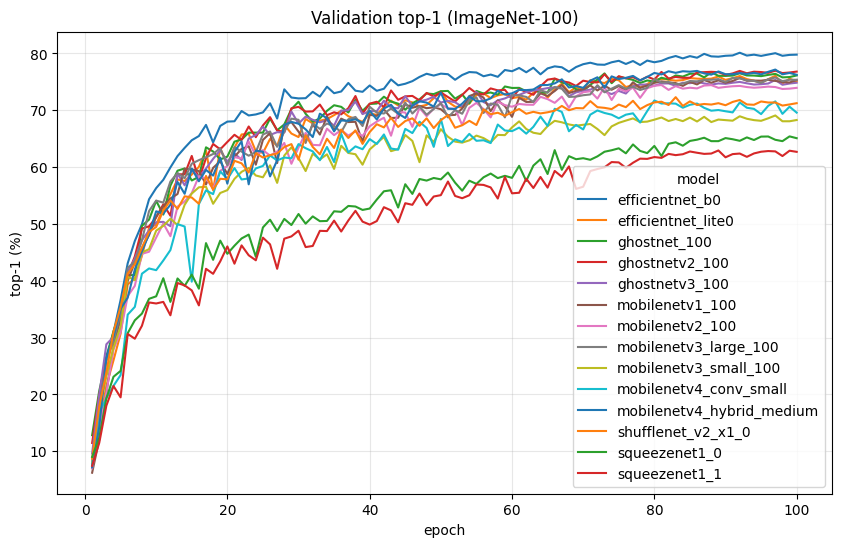

In [23]:
# Learning curves - sanity-check that the single recipe actually suits every architecture.
# A model that plateaus early or never converges is a sign the shared recipe does not fit it,
# which is itself worth reporting.
ep = store.epochs()
if not ep.empty:
    ax = ep.pivot(index="epoch", columns="model", values="top1").plot(
        figsize=(10, 6), title="Validation top-1 (ImageNet-100)")
    ax.set_xlabel("epoch"); ax.set_ylabel("top-1 (%)"); ax.grid(alpha=0.3)

In [ ]:
# Example: load a trained checkpoint (e.g. for ONNX export in the next phase)
# ck = torch.load(CKPT_DIR / "mobilenetv2_100.pt", map_location="cpu", weights_only=False)
# net, _ = build_model(ModelSpec(ck["name"], ck["source"], ck["kwargs"]), ck["num_classes"])
# net.load_state_dict(ck["model"]); net.eval()
# print(ck["top1"], ck["recipe_hash"], ck["config"]["epochs"])